# Module 1 — IBD: Smillie et al. (2019) UC atlas — QC and first embedding

**Dataset.** Smillie et al., *Cell* 2019 — 366,650 colon mucosa cells from 18 ulcerative
colitis patients (inflamed + non-inflamed biopsies) and 12 healthy controls, 51 annotated
epithelial / stromal / immune subsets. Processed data via the Single Cell Portal (SCP259);
this copy was fetched programmatically with `pertpy.data.smillie_2019()`
(script: `~/Documents/immune-endotypes/download_smillie.py`).

**This notebook:** inspect annotations -> QC -> normalize -> PCA / neighbors / UMAP /
Leiden -> first figures. Integration (scVI) is notebook 02; pseudobulk DE is notebook 03.

*Analyses of public datasets; all data credited to original authors.*

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import scanpy as sc

sc.settings.verbosity = 1
sc.settings.figdir = Path.home() / "Documents/immune-endotypes/figures"
DATA = Path.home() / "Documents/immune-endotypes/data/smillie_uc"
adata = sc.read_h5ad(DATA / "smillie_2019.h5ad")
print(adata.shape)
print(adata.obs.columns.tolist())

(365492, 18172)
['Origin', 'Subject', 'Sample', 'Location', 'Replicate', 'Health', 'Cluster', 'nGene', 'nUMI', 'Major_l1', 'Major_l2', 'Major_l3', 'Major_l4']


## 1. Look at the author annotations first

Note the exact column names printed above (disease status, biopsy location,
cell subset). Rename them into the working names used below — adjust the
right-hand sides to what the file actually carries.

In [2]:
print(adata.obs.head())
for c in adata.obs.columns:
    if adata.obs[c].dtype.name in ("category", "object"):
        print(c, "->", list(adata.obs[c].unique())[:12])

                       Origin Subject Sample Location Replicate        Health  \
N7.EpiA.AAGGCTACCCTTTA    Imm      N7   EpiA      Epi         A  Non-inflamed   
N7.EpiA.AAGGTGCTACGGAG    Imm      N7   EpiA      Epi         A  Non-inflamed   
N7.EpiA.AAGTAACTTGCTTT    Imm      N7   EpiA      Epi         A  Non-inflamed   
N7.EpiA.ACAATAACCCTCAC    Imm      N7   EpiA      Epi         A  Non-inflamed   
N7.EpiA.ACAGTTCTTCTACT    Imm      N7   EpiA      Epi         A  Non-inflamed   

                          Cluster  nGene    nUMI Major_l1  Major_l2 Major_l3  \
N7.EpiA.AAGGCTACCCTTTA     Plasma  624.0  7433.0   Immune  Lymphoid  B cells   
N7.EpiA.AAGGTGCTACGGAG  CD8+ IELs  558.0  1904.0   Immune  Lymphoid  T cells   
N7.EpiA.AAGTAACTTGCTTT  CD8+ IELs  437.0  1366.0   Immune  Lymphoid  T cells   
N7.EpiA.ACAATAACCCTCAC     Plasma  484.0  5161.0   Immune  Lymphoid  B cells   
N7.EpiA.ACAGTTCTTCTACT  CD8+ IELs  470.0  1408.0   Immune  Lymphoid  T cells   

                       Major_l4 

In [3]:
# Working names (edit the right-hand sides to match the printed columns):
# adata.obs = adata.obs.rename(columns={"Health": "condition", "Location": "site", "Cluster": "author_label"})
print([c for c in ["condition", "site", "author_label"] if c in adata.obs.columns])

[]


## 2. QC

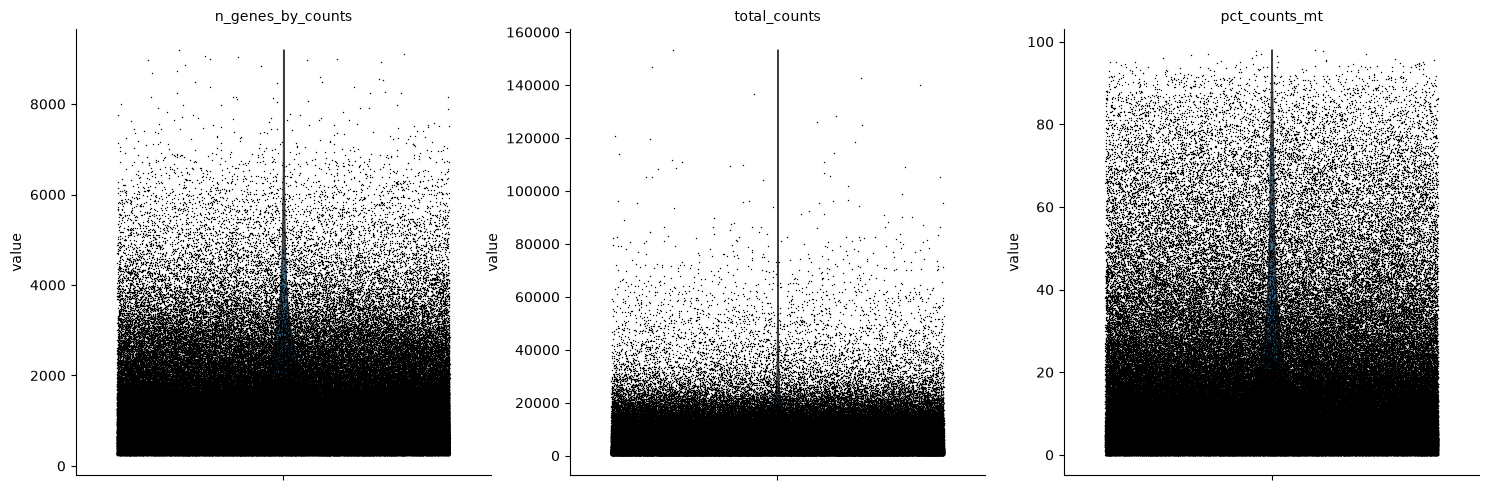

after filter: (351952, 18172)


In [4]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True, save="_qc_overall.png")
adata = adata[(adata.obs.n_genes_by_counts > 200) & (adata.obs.pct_counts_mt < 50)].copy()
adata.layers["counts"] = adata.X.copy()
print("after filter:", adata.shape)

## 3. Normalize, embed, cluster (unintegrated first pass)

In [5]:
adata.X = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
batch = "condition" if "condition" in adata.obs.columns else None
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key=batch)
sc.tl.pca(adata, n_comps=50, use_highly_variable=True)
sc.pp.neighbors(adata, n_pcs=40)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5, key_added="leiden_0.5")
print(adata)

AnnData object with n_obs × n_vars = 351952 × 18172
    obs: 'Origin', 'Subject', 'Sample', 'Location', 'Replicate', 'Health', 'Cluster', 'nGene', 'nUMI', 'Major_l1', 'Major_l2', 'Major_l3', 'Major_l4', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'leiden_0.5'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden_0.5'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'


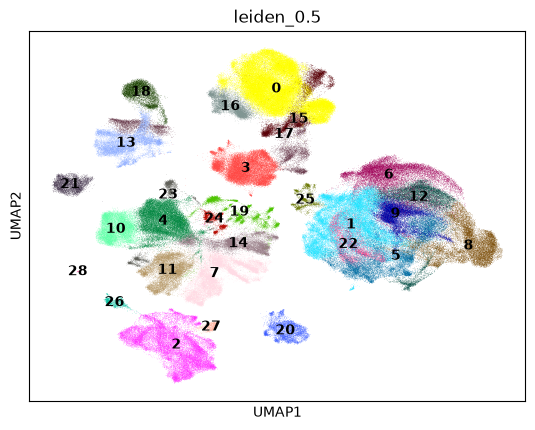

In [6]:
for col in ["condition", "site", "author_label", "leiden_0.5"]:
    if col in adata.obs.columns:
        sc.pl.umap(adata, color=col, save=f"_umap_by_{col}.png",
                   legend_loc="on data" if col in ("leiden_0.5", "author_label") else "right margin")

## 4. Save

Notebook 02 integrates donors with scVI and checks the embedding against the
author labels before any re-annotation is trusted.

In [7]:
out = DATA / "adata_qc.h5ad"
adata.write(out)
print("saved:", out)

saved: /Users/juehuayu/Documents/immune-endotypes/data/smillie_uc/adata_qc.h5ad
